<a href="https://colab.research.google.com/github/Nicolasignaciom/primera-clase-phyton/blob/main/Resumen_Catedra_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resumen de Contenidos - Cátedra 2

**Curso:** Data Science en Recursos Naturales  
**Profesor:** Marcelo Toro Miranda  
**Objetivo:** Preparar la prueba de cátedra 2, con énfasis en las librerías de limpieza y ordenamiento de datos (NumPy y Pandas).

## Contenidos
1. NumPy — Creación de arrays
2. Pandas — Limpieza y ordenamiento de datos
3. Matplotlib y Seaborn — Visualización
4. python-docx (Document) — Documentos Word
5. re — Expresiones regulares
6. pathlib (Path) — Manejo de archivos

---
## 1. NumPy

**NumPy** (Numerical Python) es la librería base para cálculo numérico. Trabaja con **arrays multidimensionales**, mucho más rápidos y eficientes que las listas de Python. Es la base sobre la que están construidas pandas, matplotlib y scikit-learn.

### Principales métodos de creación de arrays

| Método | Qué hace |
|---|---|
| `np.array()` | Convierte una lista en un array |
| `np.zeros()` | Array lleno de ceros |
| `np.ones()` | Array lleno de unos |
| `np.arange()` | Rango de valores (como `range`) |
| `np.linspace()` | N valores igualmente espaciados |
| `np.random.rand()` | Valores aleatorios entre 0 y 1 |
| `np.reshape()` | Cambia la forma del array |

In [1]:
import numpy as np

# np.array() -> lista a array
lluvias = np.array([12, 15, 8, 20, 5])
print("Array:", lluvias)

Array: [12 15  8 20  5]


In [2]:
# np.zeros() y np.ones()
ceros = np.zeros(5)
unos = np.ones((2, 3))
print("Ceros:", ceros)
print("Unos:\n", unos)

Ceros: [0. 0. 0. 0. 0.]
Unos:
 [[1. 1. 1.]
 [1. 1. 1.]]


In [3]:
# np.arange() y np.linspace()
anios = np.arange(2020, 2026)
temperaturas = np.linspace(0, 100, 5)
print("Años:", anios)
print("Temperaturas:", temperaturas)

Años: [2020 2021 2022 2023 2024 2025]
Temperaturas: [  0.  25.  50.  75. 100.]


In [4]:
# Operaciones vectorizadas: se aplican a todo el array
lluvias = np.array([12, 15, 8, 20, 5])
print("Promedio:", lluvias.mean())
print("Máximo:", lluvias.max())
print("Suma:", lluvias.sum())

Promedio: 12.0
Máximo: 20
Suma: 60


> **Para recordar:** la gran ventaja de NumPy es que las operaciones se aplican a todo el array a la vez (sin `for`).

---
## 2. Pandas

**Pandas** es la librería estrella para **manipular, limpiar y analizar datos tabulares**. Sus estructuras principales son:
- **DataFrame**: tabla con filas y columnas (como una hoja de Excel).
- **Series**: una sola columna.

### 2.1 Lectura y exploración

| Método | Qué hace |
|---|---|
| `pd.read_csv()` | Lee un CSV |
| `pd.read_excel()` | Lee un Excel |
| `df.head()` / `df.tail()` | Primeras / últimas filas |
| `df.info()` | Tipos de datos y nulos |
| `df.describe()` | Estadísticos |
| `df.shape` | (filas, columnas) |
| `df.columns` | Nombres de columnas |

In [5]:
import pandas as pd
import numpy as np

# DataFrame de ejemplo (dataset de árboles)
datos = {
    "especie": ["roble", "pino", "roble", "encina", "pino", "roble"],
    "region": ["sur", "sur", "norte", "sur", "norte", "norte"],
    "altura": [12.5, 8.0, np.nan, 6.5, 9.2, 14.0],
    "diametro": [40, 25, 38, 20, 28, 45]
}
df = pd.DataFrame(datos)
df.head()

,especie,region,altura,diametro
0,roble,sur,12.5,40
1,pino,sur,8.0,25
2,roble,norte,NaN,38
3,encina,sur,6.5,20
4,pino,norte,9.2,28


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   especie   6 non-null      object 
 1   region    6 non-null      object 
 2   altura    5 non-null      float64
 3   diametro  6 non-null      int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 324.0+ bytes


In [7]:
df.describe()

,altura,diametro
count,5.000000,6.000000
mean,10.040000,32.666667
std,3.127779,9.750214
min,6.500000,20.000000
25%,8.000000,25.750000
50%,9.200000,33.000000
75%,12.500000,39.500000
max,14.000000,45.000000


### 2.2 Selección de datos

| Método | Qué hace |
|---|---|
| `df["col"]` | Una columna |
| `df[["c1","c2"]]` | Varias columnas |
| `df.loc[]` | Por nombre |
| `df.iloc[]` | Por posición |
| `df[condición]` | Filtro booleano |

In [8]:
# Una columna
df["especie"]

,especie
0,roble
1,pino
2,roble
3,encina
4,pino
5,roble


In [9]:
# Filtro: árboles con altura mayor a 10 m
df[df["altura"] > 10]

,especie,region,altura,diametro
0,roble,sur,12.5,40
5,roble,norte,14.0,45


In [10]:
# loc: por etiqueta | iloc: por posición
print(df.loc[0, "especie"])
print(df.iloc[0:3])

roble
  especie region  altura  diametro
0   roble    sur    12.5        40
1    pino    sur     8.0        25
2   roble  norte     NaN        38


### 2.3 Limpieza de datos (MUY IMPORTANTE)

| Método | Qué hace |
|---|---|
| `df.isnull()` | Detecta nulos |
| `df.isnull().sum()` | Cuenta nulos por columna |
| `df.dropna()` | Elimina filas con nulos |
| `df.fillna(valor)` | Rellena nulos |
| `df.duplicated()` | Detecta duplicados |
| `df.drop_duplicates()` | Elimina duplicados |
| `df.astype()` | Cambia el tipo de dato |
| `df.rename()` | Renombra columnas |
| `df.replace()` | Reemplaza valores |
| `df.drop()` | Elimina filas o columnas |

In [11]:
# Detectar nulos
df.isnull().sum()

,0
especie,0
region,0
altura,1
diametro,0


In [12]:
# Rellenar nulos con el promedio
df["altura"] = df["altura"].fillna(df["altura"].mean())
df

,especie,region,altura,diametro
0,roble,sur,12.50,40
1,pino,sur,8.00,25
2,roble,norte,10.04,38
3,encina,sur,6.50,20
4,pino,norte,9.20,28
5,roble,norte,14.00,45


In [13]:
# Renombrar columnas
df = df.rename(columns={"altura": "altura_m", "diametro": "diametro_cm"})
df.head()

,especie,region,altura_m,diametro_cm
0,roble,sur,12.50,40
1,pino,sur,8.00,25
2,roble,norte,10.04,38
3,encina,sur,6.50,20
4,pino,norte,9.20,28


In [14]:
# Reemplazar valores (estandarizar texto)
df["especie"] = df["especie"].replace({"roble": "Roble", "pino": "Pino", "encina": "Encina"})
df

,especie,region,altura_m,diametro_cm
0,Roble,sur,12.50,40
1,Pino,sur,8.00,25
2,Roble,norte,10.04,38
3,Encina,sur,6.50,20
4,Pino,norte,9.20,28
5,Roble,norte,14.00,45


### 2.4 Ordenamiento y agrupación

| Método | Qué hace |
|---|---|
| `df.sort_values()` | Ordena filas |
| `df.groupby()` | Agrupa y resume |
| `df.pivot_table()` | Tabla dinámica |
| `df.merge()` | Une DataFrames (JOIN) |
| `pd.concat()` | Apila DataFrames |

In [15]:
# Ordenar por altura
df.sort_values(by="altura_m", ascending=False)

,especie,region,altura_m,diametro_cm
5,Roble,norte,14.00,45
0,Roble,sur,12.50,40
2,Roble,norte,10.04,38
4,Pino,norte,9.20,28
1,Pino,sur,8.00,25
3,Encina,sur,6.50,20


In [16]:
# groupby: altura promedio por especie
df.groupby("especie")["altura_m"].mean()

,altura_m
especie,
Encina,6.50
Pino,8.60
Roble,12.18


In [17]:
# groupby con varias operaciones
df.groupby("especie")["altura_m"].agg(["mean", "max", "min"])

,mean,max,min
especie,,,
Encina,6.50,6.5,6.50
Pino,8.60,9.2,8.00
Roble,12.18,14.0,10.04


In [18]:
# pivot_table: tabla dinámica cruzando especie y region
df.pivot_table(
    index="especie",
    columns="region",
    values="altura_m",
    aggfunc="mean"
)

region,norte,sur
especie,,
Encina,NaN,6.5
Pino,9.20,8.0
Roble,12.02,12.5


> **Diferencia clave:** `groupby()` entrega el resultado en formato **largo** (una fila por grupo). `pivot_table()` lo entrega en formato **ancho** (tabla cruzada tipo Excel).

In [19]:
# Crear una columna nueva
df["area_basal"] = 3.1416 * (df["diametro_cm"] / 2) ** 2
df["adulto"] = df["altura_m"] > 10
df

,especie,region,altura_m,diametro_cm,area_basal,adulto
0,Roble,sur,12.50,40,1256.6400,True
1,Pino,sur,8.00,25,490.8750,False
2,Roble,norte,10.04,38,1134.1176,True
3,Encina,sur,6.50,20,314.1600,False
4,Pino,norte,9.20,28,615.7536,False
5,Roble,norte,14.00,45,1590.4350,True


---
## 3. Matplotlib y Seaborn

- **Matplotlib** es la librería base para graficar.
- **Seaborn** está construida sobre matplotlib, con gráficos estadísticos más estéticos.

| Método | Qué hace |
|---|---|
| `plt.plot()` | Líneas |
| `plt.scatter()` | Dispersión |
| `plt.bar()` | Barras |
| `plt.hist()` | Histograma |
| `sns.heatmap()` | Mapa de calor |
| `sns.boxplot()` | Diagrama de caja |
| `sns.pairplot()` | Matriz de gráficos entre pares de variables (EDA) |
| `sns.scatterplot()` | Dispersión con opciones estadísticas |
| `sns.histplot()` | Histograma con curva de densidad |

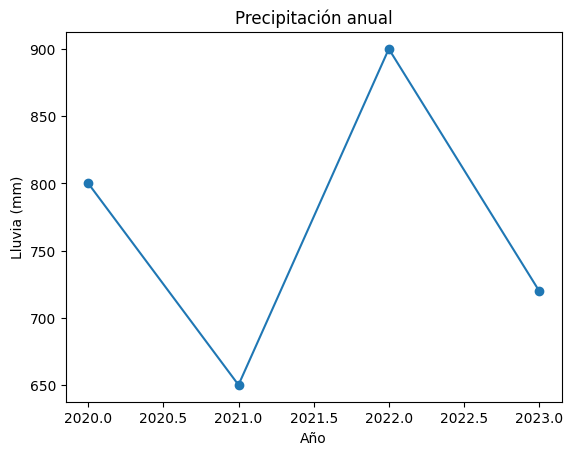

In [20]:
import matplotlib.pyplot as plt

anios = [2020, 2021, 2022, 2023]
lluvias = [800, 650, 900, 720]

plt.plot(anios, lluvias, marker="o")
plt.xlabel("Año")
plt.ylabel("Lluvia (mm)")
plt.title("Precipitación anual")
plt.show()

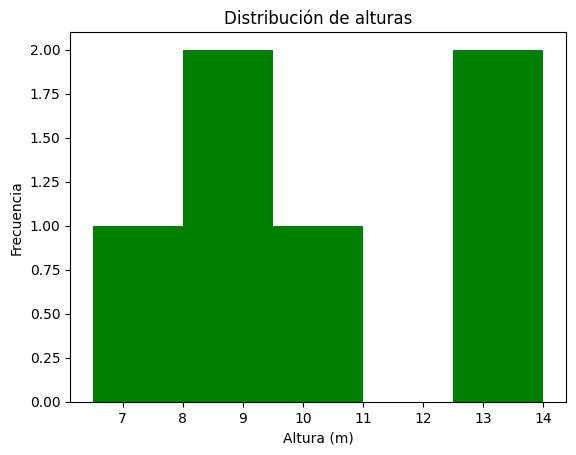

In [21]:
# Histograma
plt.hist(df["altura_m"], bins=5, color="green")
plt.xlabel("Altura (m)")
plt.ylabel("Frecuencia")
plt.title("Distribución de alturas")
plt.show()

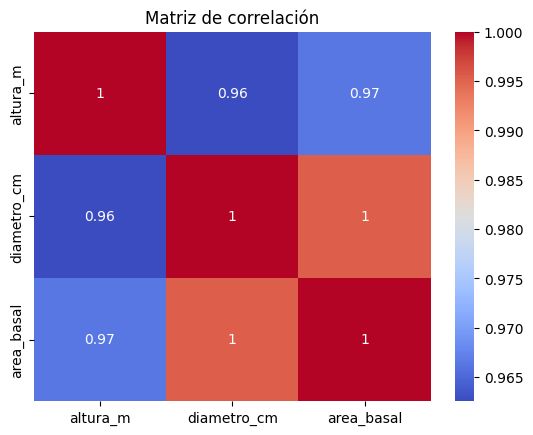

In [22]:
import seaborn as sns

# Heatmap de correlación (muy usado)
correlacion = df[["altura_m", "diametro_cm", "area_basal"]].corr()
sns.heatmap(correlacion, annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

El **heatmap** colorea una matriz: ideal para visualizar correlaciones entre variables.

### 3.1 Seaborn para Análisis Exploratorio de Datos (EDA)

**Seaborn** es especialmente útil para el **Análisis Exploratorio de Datos (EDA)**: con muy poco código permite visualizar la **distribución de variables** y las **relaciones entre pares de variables**. Esto ayuda a detectar correlaciones, agrupamientos y valores atípicos antes de aplicar cualquier modelo.

#### `sns.pairplot()` — matriz de gráficos entre variables

El `pairplot` crea una matriz donde:
- En la **diagonal** aparece la **distribución** de cada variable numérica (histograma o KDE).
- Fuera de la diagonal aparecen **scatter plots** entre cada par de variables.
- Con `hue=` se puede **colorear por una categoría** para comparar grupos.

| Parámetro | Qué hace |
|---|---|
| `data` | DataFrame con los datos |
| `vars` | Columnas numéricas a graficar |
| `hue` | Variable categórica para colorear |
| `diag_kind` | `"hist"` o `"kde"` en la diagonal |
| `kind` | `"scatter"` o `"reg"` (con línea de regresión) |
| `palette` | Paleta de colores (`"Set2"`, `"coolwarm"`, ...) |
| `corner` | Si `True`, muestra solo la mitad inferior |

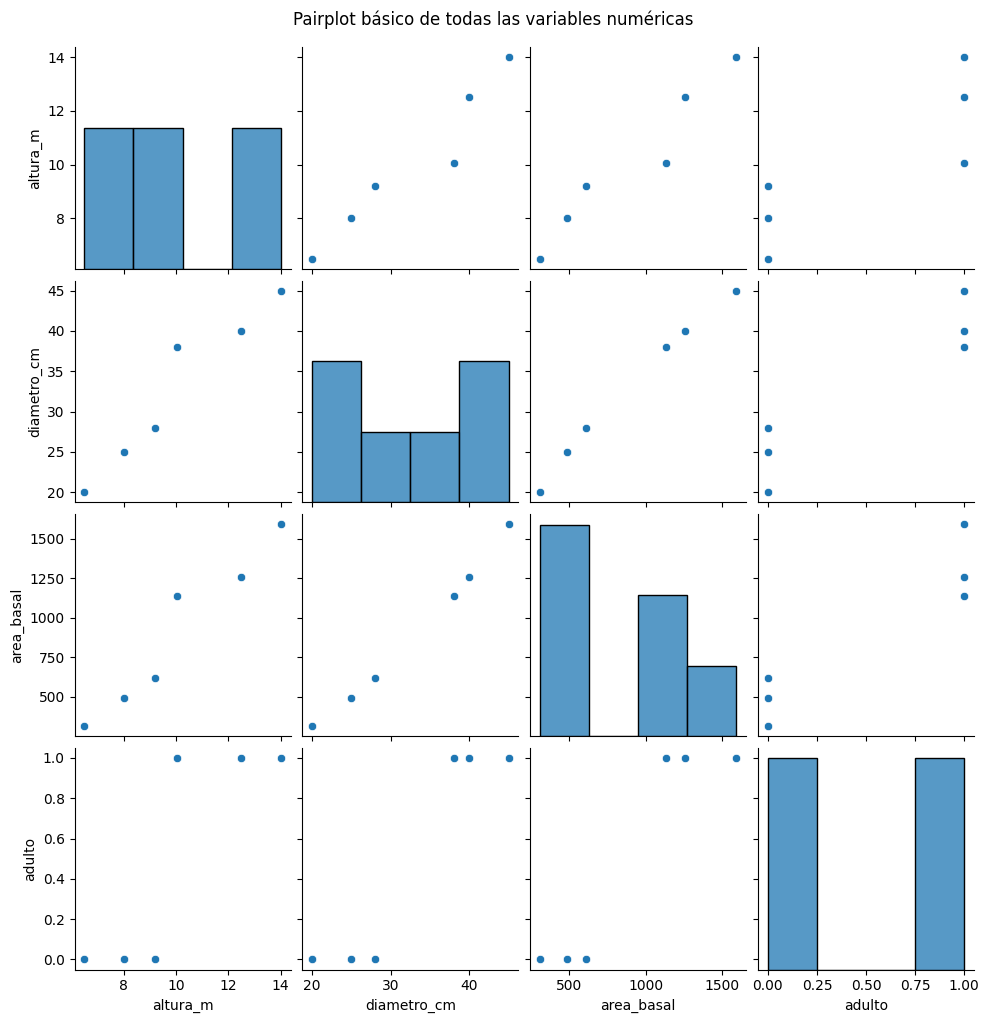

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# pairplot básico: todas las variables numéricas del DataFrame
sns.pairplot(df)
plt.suptitle("Pairplot básico de todas las variables numéricas", y=1.02)
plt.show()

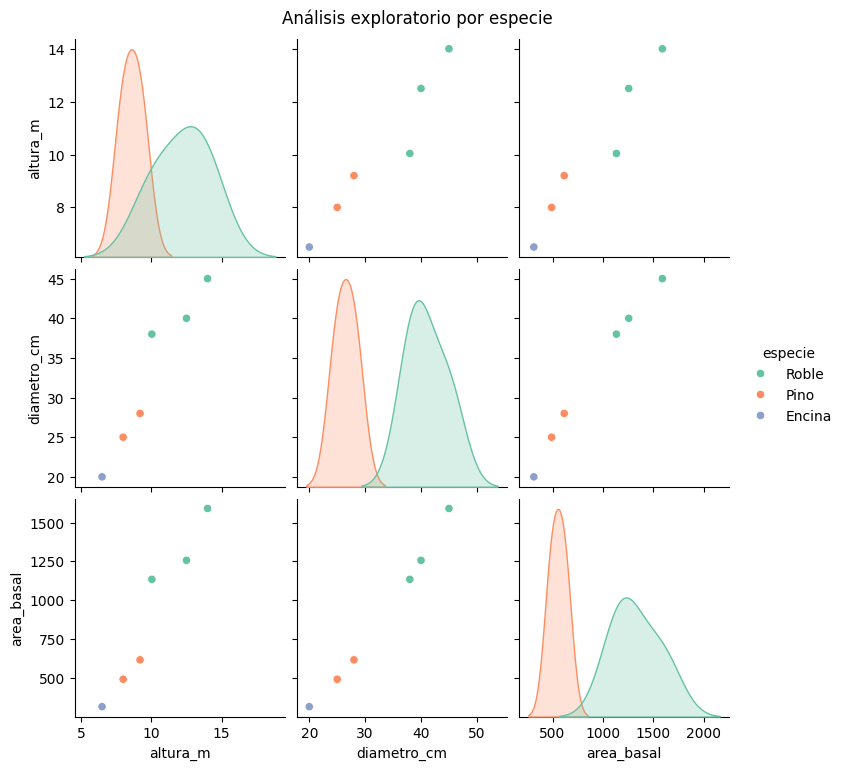

In [24]:
# pairplot coloreado por especie (ideal para EDA)
sns.pairplot(
    df,
    vars=["altura_m", "diametro_cm", "area_basal"],
    hue="especie",
    diag_kind="kde",
    palette="Set2"
)
plt.suptitle("Análisis exploratorio por especie", y=1.02)
plt.show()

> **¿Por qué es útil en EDA?** Con una sola línea de código obtienes una vista panorámica de **todas las relaciones** entre variables numéricas. Sirve para:
> - Detectar qué variables están **correlacionadas** (nubes de puntos alineadas).
> - Ver qué variables **separan bien los grupos** cuando se usa `hue`.
> - Identificar **valores atípicos** y la forma de cada distribución.

#### Otros gráficos de Seaborn para EDA

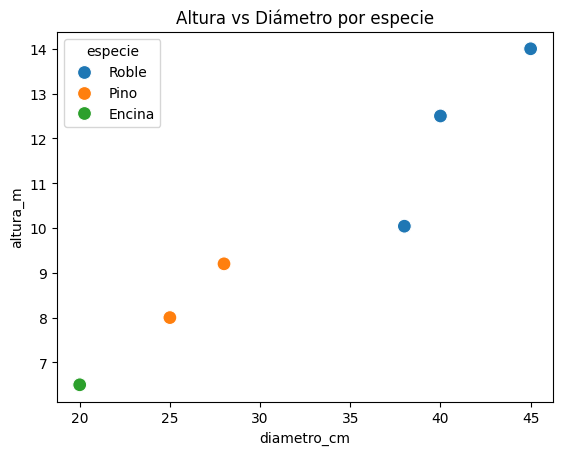

In [25]:
# scatterplot: dispersión con color por categoría
sns.scatterplot(data=df, x="diametro_cm", y="altura_m", hue="especie", s=100)
plt.title("Altura vs Diámetro por especie")
plt.show()

/tmp/ipykernel_983/1987868621.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="especie", y="altura_m", palette="Set3")


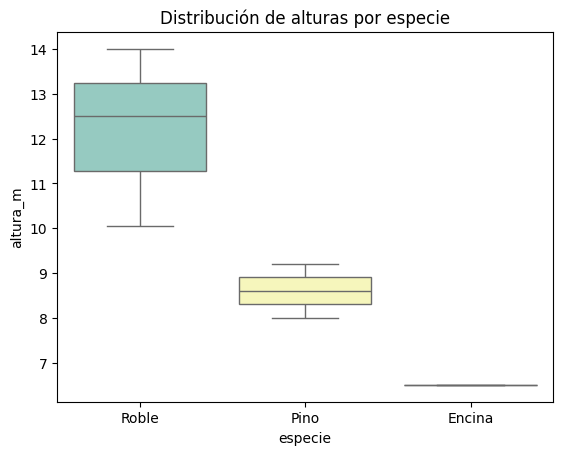

In [26]:
# boxplot: comparar la distribución entre grupos
sns.boxplot(data=df, x="especie", y="altura_m", palette="Set3")
plt.title("Distribución de alturas por especie")
plt.show()

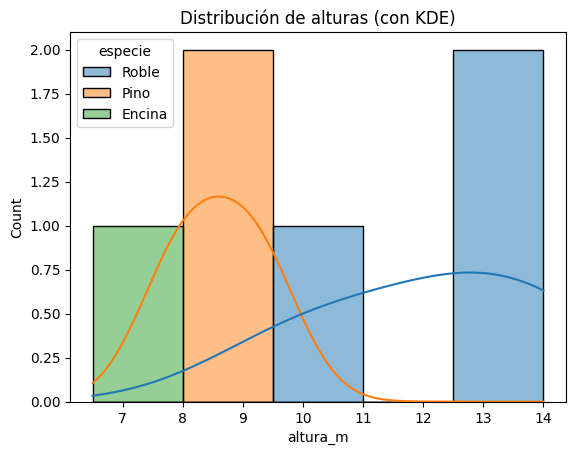

In [27]:
# histplot: histograma con curva de densidad (KDE)
sns.histplot(data=df, x="altura_m", hue="especie", kde=True, bins=5)
plt.title("Distribución de alturas (con KDE)")
plt.show()

> **Flujo típico de EDA con Seaborn:**
> 1. `df.describe()` → estadísticos básicos.
> 2. `sns.histplot()` → ver la distribución de cada variable.
> 3. `sns.pairplot()` → ver todas las relaciones entre variables numéricas de un vistazo.
> 4. `sns.heatmap(df.corr())` → cuantificar las correlaciones observadas.
> 5. `sns.boxplot()` → comparar grupos y detectar outliers.

---
## 4. python-docx — Documentos Word

La librería **python-docx** permite crear y modificar archivos .docx: títulos, párrafos, tablas e imágenes.

| Método | Qué hace |
|---|---|
| `Document()` | Crea / abre un documento |
| `.add_heading()` | Título |
| `.add_paragraph()` | Párrafo |
| `.add_table()` | Tabla |
| `.add_picture()` | Imagen |
| `.save()` | Guarda el archivo |

In [28]:
!pip install python-docx
from docx import Document

doc = Document()
doc.add_heading("Informe de Terreno", level=1)
doc.add_paragraph("En la salida se midieron 50 árboles.")
doc.add_paragraph("La especie predominante fue el roble.")
doc.save("informe.docx")
print("Documento guardado: informe.docx")

Documento guardado: informe.docx


In [29]:
# Agregar una tabla
doc = Document()
doc.add_heading("Resumen por especie", level=2)

tabla = doc.add_table(rows=2, cols=2)
tabla.cell(0, 0).text = "Especie"
tabla.cell(0, 1).text = "Cantidad"
tabla.cell(1, 0).text = "Roble"
tabla.cell(1, 1).text = "25"

doc.save("tabla.docx")
print("Documento con tabla guardado")

Documento con tabla guardado


---
## 5. re — Expresiones regulares

El módulo **re** permite buscar **patrones de texto** en cadenas. Muy útil para limpiar datos textuales.

| Método | Qué hace |
|---|---|
| `re.search()` | Primera coincidencia |
| `re.match()` | Al inicio |
| `re.findall()` | Todas las coincidencias |
| `re.sub()` | Reemplaza |
| `re.split()` | Divide por patrón |

### Patrones más usados

| Patrón | Significa |
|---|---|
| `\d` | Un dígito |
| `\w` | Letra, número o `_` |
| `\s` | Espacio |
| `+` | Uno o más |
| `*` | Cero o más |
| `[abc]` | Cualquiera de esas letras |

In [30]:
import re

# search: primera coincidencia
texto = "El árbol mide 12.5 metros"
resultado = re.search(r"\d+\.\d+", texto)
print(resultado.group())  # 12.5

12.5


In [31]:
# findall: todas las coincidencias
texto = "25 robles, 12 pinos, 7 encinas"
numeros = re.findall(r"\d+", texto)
print(numeros)

['25', '12', '7']


In [32]:
# sub: reemplazar (limpieza de texto)
texto = "Roble#@ del sur!!"
limpio = re.sub(r"[^A-Za-z ]", "", texto)
print(limpio)

Roble del sur


In [33]:
# split: dividir texto
texto = "roble,pino;encina quillay"
partes = re.split(r"[,;\s]", texto)
print(partes)

['roble', 'pino', 'encina', 'quillay']


---
## 6. pathlib (Path) — Manejo de archivos

**pathlib** entrega una forma moderna y orientada a objetos de manejar rutas y archivos. Funciona en Windows, Linux y Mac.

| Método | Qué hace |
|---|---|
| `Path("ruta")` | Crea un objeto Path |
| `.exists()` | ¿Existe? |
| `.is_file()` / `.is_dir()` | ¿Archivo / carpeta? |
| `.mkdir()` | Crea carpeta |
| `.iterdir()` | Lista contenido |
| `.glob("*.csv")` | Busca por patrón |
| `.name` / `.stem` / `.suffix` | Nombre / sin extensión / extensión |
| `.parent` | Carpeta contenedora |

In [34]:
from pathlib import Path

archivo = Path("informe.docx")
print("¿Existe?:", archivo.exists())

¿Existe?: True


In [35]:
# Partes de una ruta
p = Path("C:/datos/terreno/arboles.csv")
print("name  :", p.name)
print("stem  :", p.stem)
print("suffix:", p.suffix)
print("parent:", p.parent)

name  : arboles.csv
stem  : arboles
suffix: .csv
parent: C:/datos/terreno


In [36]:
# Crear una carpeta (si no existe)
Path("resultados").mkdir(exist_ok=True)
print("Carpeta 'resultados' lista")

Carpeta 'resultados' lista


In [37]:
# Listar archivos CSV en una carpeta
carpeta = Path(".")
for archivo in carpeta.glob("*.md"):
    print(archivo.name)

In [38]:
# Unir rutas con /
base = Path("datos")
ruta = base / "arboles.csv"
print(ruta)

datos/arboles.csv


---
## Consejos finales para la prueba

1. **NumPy**: arrays + operaciones **vectorizadas** (sin `for`).
2. **Pandas**: dominar `read_csv`, `head`, `info`, `describe`, `dropna`, `fillna`, `groupby`, `pivot_table`.
3. **Diferencia clave**: `groupby` (formato largo) vs `pivot_table` (formato ancho / tabla dinámica).
4. **Matplotlib/Seaborn**: gráfico básico y **heatmap** de correlación.
5. **Document()**: `add_heading`, `add_paragraph`, `add_table`, `save`.
6. **re**: patrones (`\d`, `\w`, `+`, `*`) y métodos `search`, `findall`, `sub`.
7. **Path**: `exists`, `glob`, `name`, `stem`, `suffix` y el operador `/` para unir rutas.

¡Éxito en la prueba!